In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
import statsmodels.api as sm

from analysis import *

In [2]:
scenarios = ['full_pipeline', 'full_pipeline_TQ14', 'full_pipeline_MP0.95', 'no_cluster']

df2 = (
    df.assign(
        scenario=pd.Categorical(df['scenario'], categories=scenarios, ordered=True)
    )
    .query('scenario.isin(@scenarios)')
    .groupby('scenario', observed=False)
    .size()
    .reset_index(name='count')
)
df2['label'] = ['Exp. data', 'Exp. data\n(TQ 14)', 'Exp. data\n(MP 0.95)', 'Exp. data\n(no cluster)']
df2

/var/folders/59/35nb2tq50vz3vpwjkwkzppvh0000gn/T/ipykernel_6147/3922863477.py:5: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  scenario=pd.Categorical(df['scenario'], categories=scenarios, ordered=True)


,scenario,count,label
0,full_pipeline,277,Exp. data
1,full_pipeline_TQ14,278,Exp. data\n(TQ 14)
2,full_pipeline_MP0.95,269,Exp. data\n(MP 0.95)
3,no_cluster,332,Exp. data\n(no cluster)


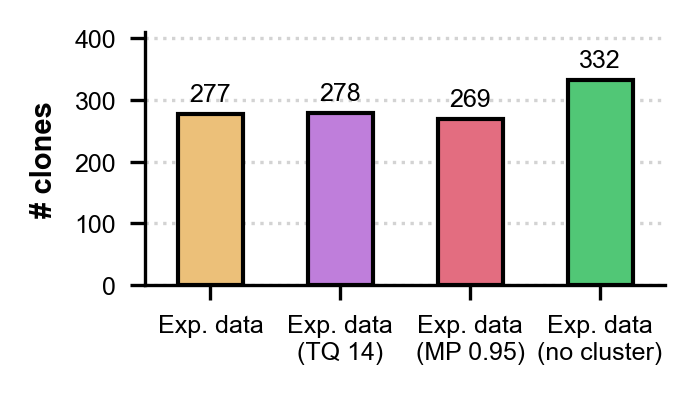

In [5]:
plt.rcParams.update(small_label_settings)
fig, ax = plt.subplots(figsize = (2.2, 1.2), dpi = 300, constrained_layout = True)

sns.barplot(data = df2, x = 'label', y = 'count', hue = 'label',
    palette = palette, legend = False, edgecolor = 'black',
    width = 0.5, zorder = 2, ax = ax
)

for patch in ax.patches:
    height = patch.get_height()
    x = patch.get_x() + patch.get_width() / 2

    ax.annotate(int(height), xy=(x, height), xytext=(0, 2),
        textcoords="offset points", ha='center', va='bottom',
        fontsize=6, color='black'
    )

for s in ['top', 'right']:
    ax.spines[s].set_visible(False)

ax.set_xlabel('')
ax.set_ylabel('# clones', fontweight = 'bold')
ax.set_ylim([0, 410])

ax.grid(True, linestyle=':', linewidth=0.8, color='lightgray', axis = 'y', zorder=-1)

# plt.tight_layout()

filepath = os.path.join('images', 'clone_count.svg')
plt.savefig(filepath, pad_inches = 0)